# Banking77 Dataset — Data Exploration

## Project Overview
This notebook explores the Banking77 dataset for a support-ticket intent classification project.

## Objectives
- Load and inspect the training and test datasets.
- Examine dataset dimensions, columns, and data types.
- Check missing values and duplicate texts.
- Analyze the distribution of intent categories.
- Inspect text length and representative samples.
- Identify potential data quality issues before model training.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "app"))

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from pathlib import Path

from config import RAW_TRAIN_FILE, RAW_TEST_FILE

In [3]:
train_df = pd.read_csv(RAW_TRAIN_FILE)
test_df = pd.read_csv(RAW_TEST_FILE)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())

Train shape: (10003, 2)
Test shape: (3080, 2)


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


In [4]:
print("Train columns:", train_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())

print("\nTrain information:")
train_df.info()

print("\nTest information:")
test_df.info()

Train columns: ['text', 'category']
Test columns: ['text', 'category']

Train information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      10003 non-null  object
 1   category  10003 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB

Test information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3080 entries, 0 to 3079
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      3080 non-null   object
 1   category  3080 non-null   object
dtypes: object(2)
memory usage: 48.3+ KB


In [5]:
print("Missing values in train:")
display(train_df.isnull().sum())

print("\nMissing values in test:")
display(test_df.isnull().sum())

Missing values in train:


text        0
category    0
dtype: int64


Missing values in test:


text        0
category    0
dtype: int64

In [7]:
print("Duplicate rows in train:", train_df.duplicated().sum())
print("Duplicate texts in train:", train_df["text"].duplicated().sum())

print("Duplicate rows in test:", test_df.duplicated().sum())
print("Duplicate texts in test:", test_df["text"].duplicated().sum())

Duplicate rows in train: 0
Duplicate texts in train: 0
Duplicate rows in test: 0
Duplicate texts in test: 0


In [8]:
print("Number of train samples:", len(train_df))
print("Number of test samples:", len(test_df))

print("Number of train category:", train_df["category"].nunique())
print("Number of test category:", test_df["category"].nunique())

print("\nTrain category distribution:")
display(train_df["category"].value_counts().head(10))

Number of train samples: 10003
Number of test samples: 3080
Number of train category: 77
Number of test category: 77

Train category distribution:


category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
transaction_charged_twice                           175
declined_cash_withdrawal                            173
transfer_fee_charged                                172
transfer_not_received_by_recipient                  171
balance_not_updated_after_bank_transfer             171
Name: count, dtype: int64

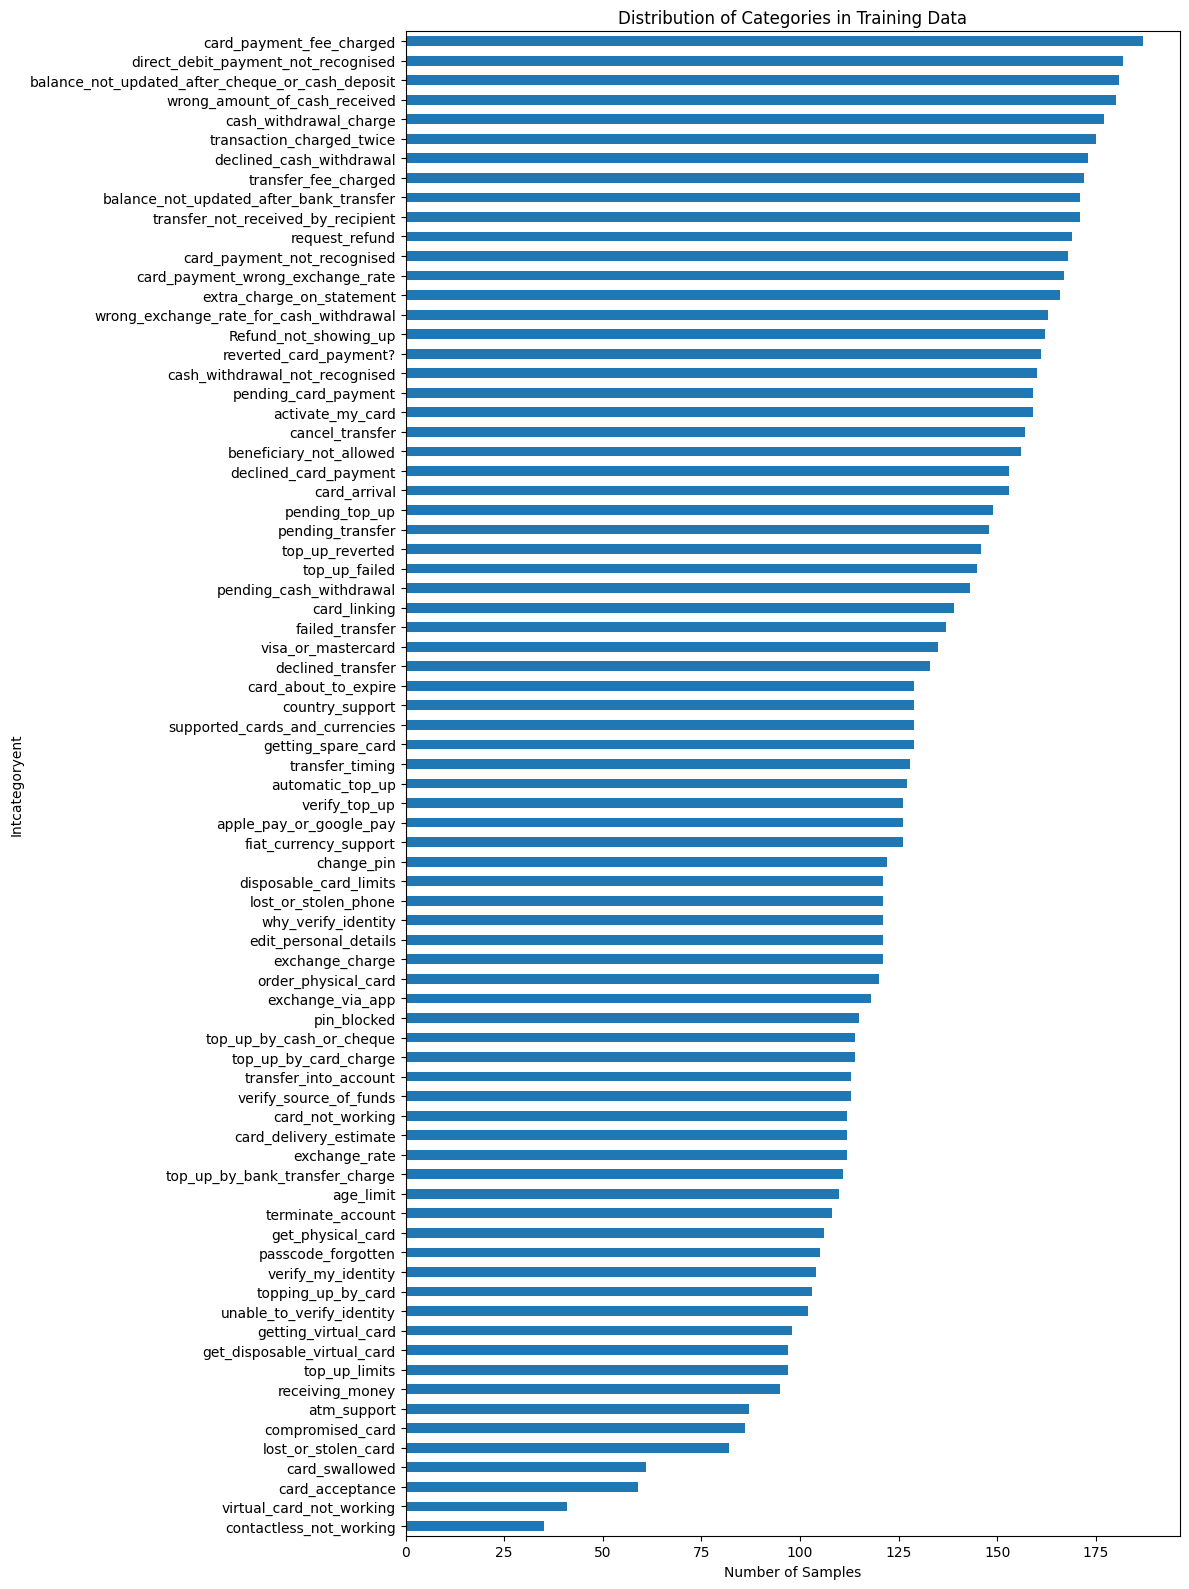

In [9]:
intent_counts = train_df["category"].value_counts().sort_values()

plt.figure(figsize=(12, 16))
intent_counts.plot(kind="barh")

plt.title("Distribution of Categories in Training Data")
plt.xlabel("Number of Samples")
plt.ylabel("Intcategoryent")

plt.tight_layout()
plt.show()

count    10003.000000
mean        59.473758
std         40.867901
min         13.000000
25%         36.000000
50%         47.000000
75%         64.000000
max        433.000000
Name: text_length, dtype: float64


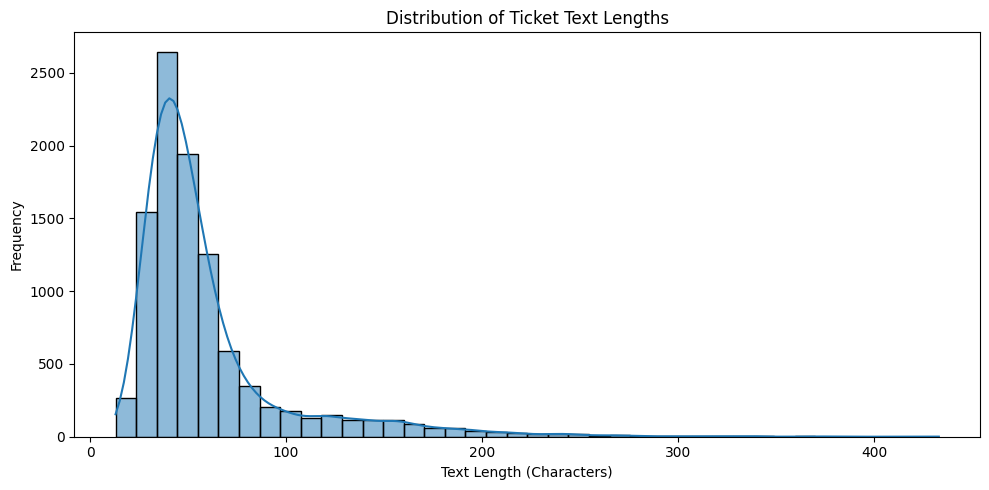

In [10]:
train_df["text_length"] = train_df["text"].astype(str).str.len()

print(train_df["text_length"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(train_df["text_length"], bins=40, kde=True)

plt.title("Distribution of Ticket Text Lengths")
plt.xlabel("Text Length (Characters)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [11]:
pd.set_option("display.max_colwidth", 200)

for category in train_df["category"].value_counts().head(5).index:
    print(f"\nIntent: {category}")

    display(
        train_df.loc[
            train_df["category"] == category,
            ["text", "category"]
        ].head(3)
    )


Intent: card_payment_fee_charged


,text,category
2511,There was a fee charged when I paid with my card.,card_payment_fee_charged
2512,I received a fee I should not have.,card_payment_fee_charged
2513,Why am I being a charged for using my card?,card_payment_fee_charged



Intent: direct_debit_payment_not_recognised


,text,category
4632,"Hi, i found a large amount payment in my old statements which i am sure was not made by me. I am aware that the time has passed but is there a way to raise a dispute for this payment now?",direct_debit_payment_not_recognised
4633,what is the word?,direct_debit_payment_not_recognised
4634,Please help my find out why there is an odd direct debit in my records.,direct_debit_payment_not_recognised



Intent: balance_not_updated_after_cheque_or_cash_deposit


,text,category
3301,Why is my last cheque deposit taking so long?,balance_not_updated_after_cheque_or_cash_deposit
3302,I am still waiting for a the cash I deposited this morning,balance_not_updated_after_cheque_or_cash_deposit
3303,"I tried using a check to update my balance, but it isn't work? Is something wrong?",balance_not_updated_after_cheque_or_cash_deposit



Intent: wrong_amount_of_cash_received


,text,category
2331,Why did I only receive a partial amount of what I tried to withdraw?,wrong_amount_of_cash_received
2332,my atm transaction was wrong,wrong_amount_of_cash_received
2333,why did i only get 20.00,wrong_amount_of_cash_received



Intent: cash_withdrawal_charge


,text,category
9338,Why is there a charge when I took out money?,cash_withdrawal_charge
9339,Why have I been charged a fee for cash withdrawal?,cash_withdrawal_charge
9340,I made a cash withdrawl and there is a charge. What is this?,cash_withdrawal_charge


In [12]:
train_texts = set(train_df["text"].astype(str))
test_texts = set(test_df["text"].astype(str))

overlap = train_texts.intersection(test_texts)

print("Unique train texts:", len(train_texts))
print("Unique test texts:", len(test_texts))
print("Texts appearing in both sets:", len(overlap))

Unique train texts: 10003
Unique test texts: 3080
Texts appearing in both sets: 0


In [13]:
category_counts = train_df["category"].value_counts()

print("Minimum samples per category:", category_counts.min())
print("Maximum samples per category:", category_counts.max())
print("Mean samples per category:", category_counts.mean())
print("Standard deviation:", category_counts.std())

print("\nLeast frequent categories:")
display(category_counts.sort_values().head(10))

Minimum samples per category: 35
Maximum samples per category: 187
Mean samples per category: 129.9090909090909
Standard deviation: 32.9422068965531

Least frequent categories:


category
contactless_not_working        35
virtual_card_not_working       41
card_acceptance                59
card_swallowed                 61
lost_or_stolen_card            82
compromised_card               86
atm_support                    87
receiving_money                95
top_up_limits                  97
get_disposable_virtual_card    97
Name: count, dtype: int64

In [14]:
train_texts = set(train_df["text"].astype(str))
test_texts = set(test_df["text"].astype(str))

overlap = train_texts.intersection(test_texts)

print("Unique train texts:", len(train_texts))
print("Unique test texts:", len(test_texts))
print("Texts appearing in both sets:", len(overlap))

Unique train texts: 10003
Unique test texts: 3080
Texts appearing in both sets: 0


In [15]:
train_df["text_length"] = train_df["text"].str.len()

category_lengths = (
    train_df.groupby("category")["text_length"]
    .agg(["mean", "median", "min", "max"])
    .sort_values("mean")
)

display(category_lengths.head(10))

,mean,median,min,max
category,,,,
get_physical_card,32.867925,30.0,13,71
top_up_limits,35.082474,33.0,13,80
order_physical_card,35.725000,33.5,18,80
atm_support,36.873563,35.0,16,72
card_acceptance,37.237288,34.0,20,58
passcode_forgotten,37.742857,35.0,13,86
top_up_by_cash_or_cheque,38.605263,38.0,18,75
visa_or_mastercard,39.274074,37.0,18,78
getting_virtual_card,41.224490,39.0,21,94


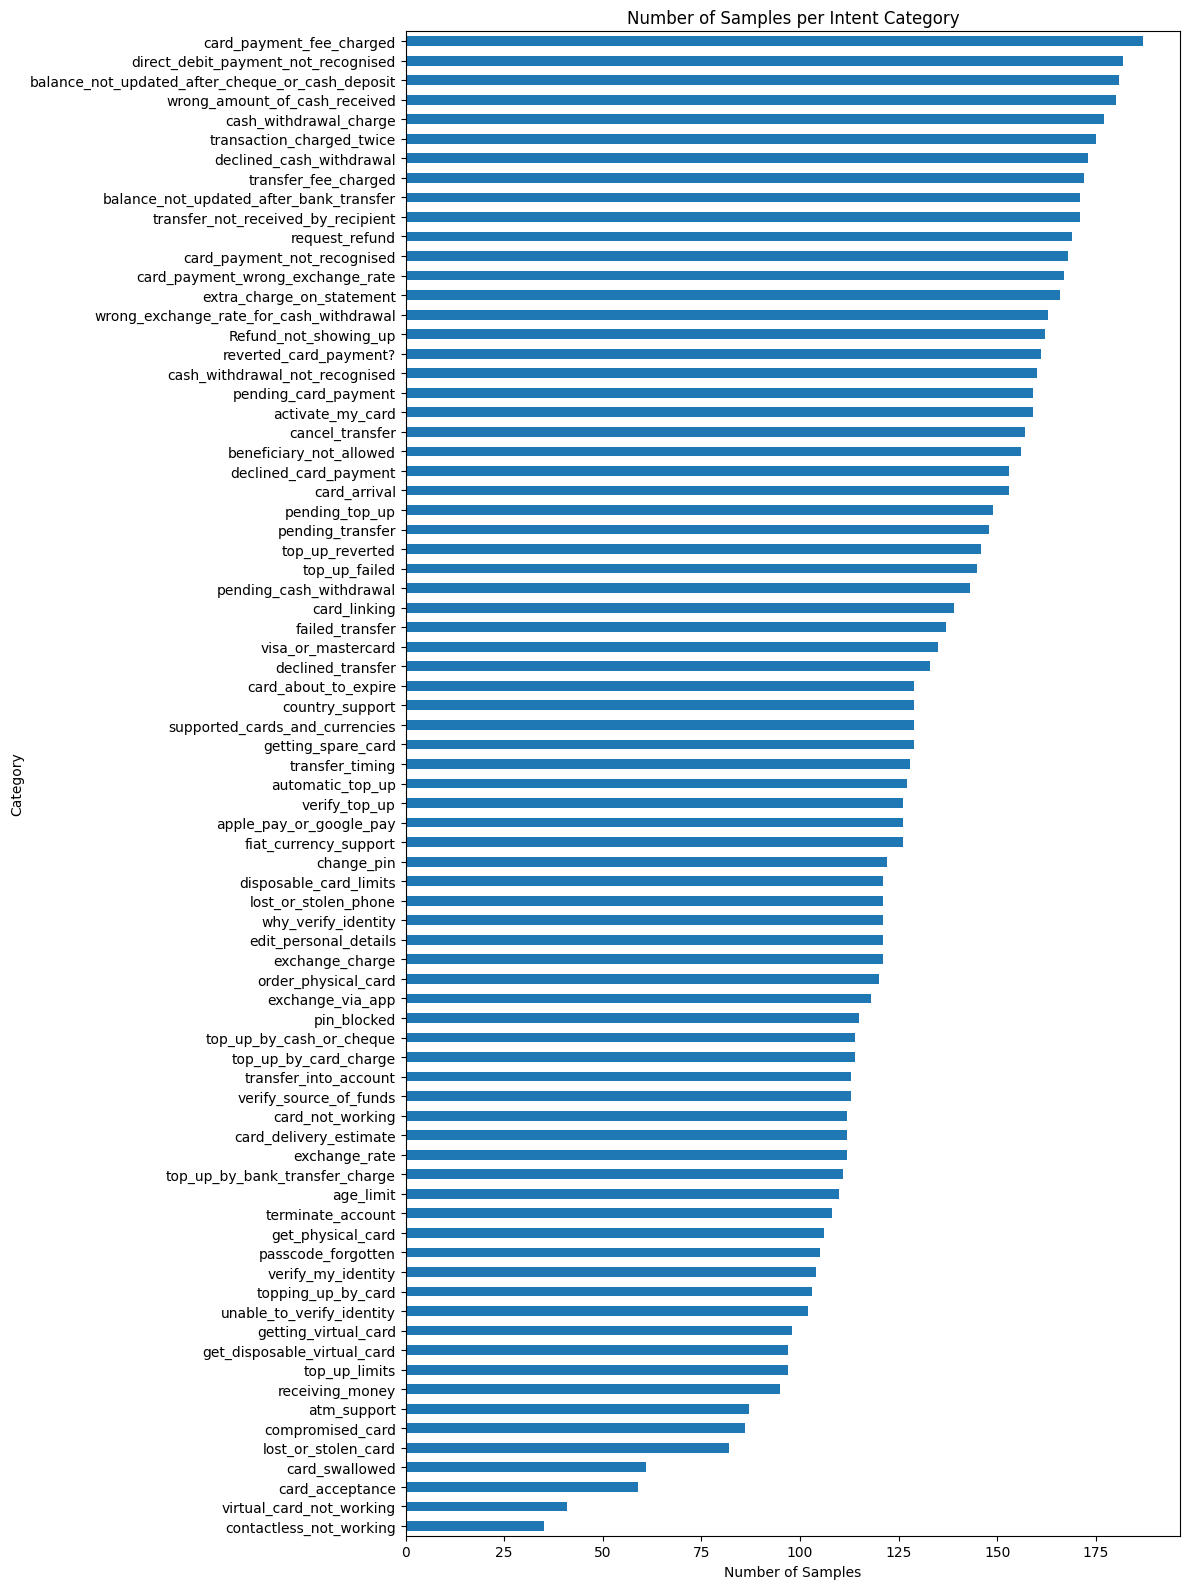

In [16]:
category_counts = train_df["category"].value_counts().sort_values()

plt.figure(figsize=(12, 16))
category_counts.plot(kind="barh")

plt.title("Number of Samples per Intent Category")
plt.xlabel("Number of Samples")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

## Data Exploration Summary

The Banking77 dataset contains 10,003 training samples and 3,080 test samples across 77 intent categories. No missing values, duplicate rows, or duplicate texts were found within either dataset. No exact text overlap was found between the training and test sets.

The number of training samples varies across categories, ranging from 35 to 187. Therefore, both overall classification performance and per-category performance should be evaluated.

The text samples are generally short, making TF-IDF-based methods a useful baseline before experimenting with Transformer-based models.

The dataset is ready for baseline model development, subject to further evaluation of classification errors and model performance.